# Experiment 1 — Evolution from Perceptron to Multi-Layer Perceptron (MLP)
**Foundations of Deep Learning**

| | |
|---|---|
| **Name** | Acchute Kashyap |
| **Reg. No** | CH.SC.U4CSE23003 |
| **Date** | 16th October 2026 |

**Objective:** Understand why the single-layer perceptron failed for certain problems and how the Multi-Layer Perceptron (MLP) overcame these limitations.

In [45]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from matplotlib.patches import Circle, FancyBboxPatch
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})

## Task 1 — Architecture of a single-layer perceptron

A single-layer perceptron has **no hidden layer**: the input features are connected directly to one output neuron.

1. **Inputs** $x_1, x_2, \dots, x_n$ carry the features.
2. Each input has a **weight** $w_i$ that sets how strongly it influences the output.
3. The neuron forms the **weighted sum** $z = w_1x_1 + w_2x_2 + b$, where $b$ is the **bias** (it shifts the decision threshold).
4. An **activation function** $f$ (step or sigmoid) turns $z$ into the output $\hat y = f(z)$.

Because $z=0$ is the equation of a straight line (a hyperplane in higher dimensions), the perceptron can only separate classes with **one straight line** — i.e. it only solves *linearly separable* problems.

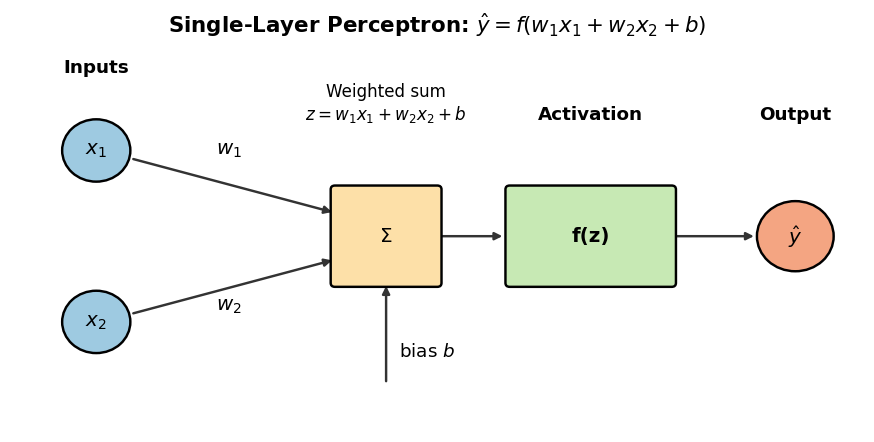

In [46]:
fig, ax = plt.subplots(figsize=(10, 4.6)); ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.axis('off')

def node(x, y, label, color, r=0.4):
    ax.add_patch(Circle((x, y), r, fc=color, ec='black', lw=1.6, zorder=3))
    ax.text(x, y, label, ha='center', va='center', fontsize=13, fontweight='bold', zorder=4)

def box(x, y, w, h, label, color):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle='round,pad=0.05', fc=color, ec='black', lw=1.6, zorder=3))
    ax.text(x, y, label, ha='center', va='center', fontsize=13, fontweight='bold', zorder=4)

def arrow(p, q): ax.annotate('', xy=q, xytext=p, arrowprops=dict(arrowstyle='-|>', lw=1.6, color='#333'), zorder=2)

node(1, 3.6, '$x_1$', '#9ecae1'); node(1, 1.4, '$x_2$', '#9ecae1')
box(4.4, 2.5, 1.2, 1.2, r'$\Sigma$', '#fde0a8'); box(6.8, 2.5, 1.9, 1.2, 'f(z)', '#c7e9b4'); node(9.2, 2.5, r'$\hat{y}$', '#f4a582', r=0.45)
arrow((1.4, 3.5), (3.8, 2.8)); arrow((1.4, 1.5), (3.8, 2.2))
arrow((5.0, 2.5), (5.8, 2.5)); arrow((7.75, 2.5), (8.75, 2.5)); arrow((4.4, 0.6), (4.4, 1.9))
ax.text(2.4, 3.55, '$w_1$', fontsize=13); ax.text(2.4, 1.55, '$w_2$', fontsize=13); ax.text(4.55, 0.95, 'bias $b$', fontsize=12)
ax.text(1, 4.6, 'Inputs', ha='center', fontsize=12, fontweight='bold'); ax.text(4.4, 4.0, 'Weighted sum\n$z=w_1x_1+w_2x_2+b$', ha='center', fontsize=11)
ax.text(6.8, 4.0, 'Activation', ha='center', fontsize=12, fontweight='bold'); ax.text(9.2, 4.0, 'Output', ha='center', fontsize=12, fontweight='bold')
ax.set_title('Single-Layer Perceptron: $\\hat{y} = f(w_1x_1 + w_2x_2 + b)$', fontsize=14, fontweight='bold'); plt.show()

**Quick experiment:** train a classic perceptron (perceptron learning rule) on the logic gates AND, OR, NAND and XOR. If the architecture is enough, accuracy should reach 100%.

In [47]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
gates = {'AND': [0, 0, 0, 1], 'OR': [0, 1, 1, 1], 'NAND': [1, 1, 1, 0], 'XOR': [0, 1, 1, 0]}

def train_perceptron(X, t, epochs=100, lr=0.1):
    w, b = np.zeros(2), 0.0
    for _ in range(epochs):
        for xi, ti in zip(X, t):
            err = ti - int(w @ xi + b > 0)
            w, b = w + lr * err * xi, b + lr * err
    pred = (X @ w + b > 0).astype(int)
    return w, b, (pred == t).mean()

rows = []
for g, t in gates.items():
    w, b, acc = train_perceptron(X, np.array(t))
    rows.append({'Gate': g, 'w1': round(w[0], 2), 'w2': round(w[1], 2), 'bias': round(b, 2), 'Accuracy': f'{acc*100:.0f}%'})
pd.DataFrame(rows)

,Gate,w1,w2,bias,Accuracy
0,AND,0.2,0.1,-0.2,100%
1,OR,0.1,0.1,0.0,100%
2,NAND,-0.2,-0.1,0.2,100%
3,XOR,-0.1,0.0,0.1,50%


## Task 2 — XOR truth table

In [48]:
x1, x2 = np.array([0, 0, 1, 1]), np.array([0, 1, 0, 1])
xor_table = pd.DataFrame({'x1': x1, 'x2': x2, 'XOR (x1 ⊕ x2)': x1 ^ x2})
xor_table

,x1,x2,XOR (x1 ⊕ x2)
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


## Task 3 — XOR data points in a 2-D coordinate system

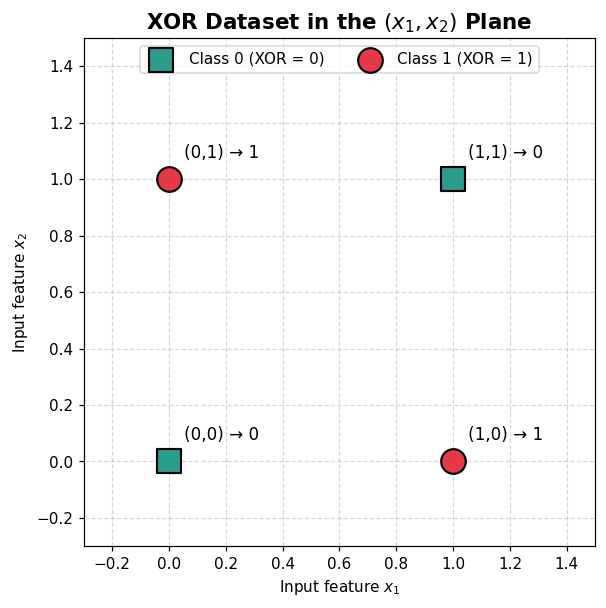

In [49]:
y = x1 ^ x2                      # labels [0, 1, 1, 0]
X = np.c_[x1, x2].astype(float)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*X[y == 0].T, c='#2a9d8f', marker='s', s=260, edgecolor='black', lw=1.4, label='Class 0 (XOR = 0)', zorder=3)
ax.scatter(*X[y == 1].T, c='#e63946', marker='o', s=260, edgecolor='black', lw=1.4, label='Class 1 (XOR = 1)', zorder=3)
for (a, b), t in zip(X, y):
    ax.annotate(f'({int(a)},{int(b)}) → {t}', (a, b), xytext=(10, 14), textcoords='offset points', fontsize=11)
ax.set(xlim=(-0.3, 1.5), ylim=(-0.3, 1.5), xlabel='Input feature $x_1$', ylabel='Input feature $x_2$')
ax.set_title('XOR Dataset in the $(x_1, x_2)$ Plane', fontsize=14, fontweight='bold')
ax.grid(True, ls='--', alpha=0.5); ax.legend(loc='upper center', ncol=2); plt.show()

## Task 4 — Mathematical proof that XOR is not linearly separable

**Claim.** There are no real numbers $w_1, w_2, b$ such that the rule $\hat y = 1 \iff w_1x_1 + w_2x_2 + b > 0$ classifies all four XOR points correctly.

**Proof (by contradiction).** Suppose such $w_1, w_2, b$ exist. Then every point must satisfy:

| Point | Required class | Inequality |
|---|---|---|
| $(0,0)$ | 0 | $b \le 0$ … (1) |
| $(0,1)$ | 1 | $w_2 + b > 0$ … (2) |
| $(1,0)$ | 1 | $w_1 + b > 0$ … (3) |
| $(1,1)$ | 0 | $w_1 + w_2 + b \le 0$ … (4) |

Add inequalities (2) and (3):

$$w_1 + w_2 + 2b > 0 \quad\Longrightarrow\quad w_1 + w_2 + b > -b .$$

From (1), $b \le 0$, so $-b \ge 0$, and therefore

$$w_1 + w_2 + b > -b \ge 0 \quad\Longrightarrow\quad w_1 + w_2 + b > 0 .$$

But inequality (4) demands $w_1 + w_2 + b \le 0$. This is a **contradiction**. Hence no $(w_1, w_2, b)$ exists, and **XOR is not linearly separable**. $\blacksquare$

**Geometric view.** The points $(0,1)$ and $(1,0)$ (class 1) have midpoint $(0.5, 0.5)$, which is also the midpoint of $(0,0)$ and $(1,1)$ (class 0). The convex hulls of the two classes (the two diagonals of the unit square) **intersect**, and two classes whose convex hulls intersect can never be split by a line.

**Numerical check:** brute-force search over 226,981 candidate lines $(w_1, w_2, b) \in [-3,3]^3$ and record the best accuracy any of them achieves.

In [50]:
g = np.linspace(-3, 3, 61)
W1, W2, B = np.meshgrid(g, g, g, indexing='ij')
pred = (W1[..., None] * X[:, 0] + W2[..., None] * X[:, 1] + B[..., None]) > 0     # shape (61,61,61,4)
acc = (pred == y.astype(bool)).mean(-1)
print(f'Lines tested                 : {acc.size:,}')
print(f'Best accuracy of any line    : {acc.max()*100:.0f}%')
print(f'Lines that classify all 4 OK : {(acc == 1).sum()}')

Lines tested                 : 226,981
Best accuracy of any line    : 75%
Lines that classify all 4 OK : 0


## Task 5 — Why no single linear decision boundary can classify XOR

A linear decision boundary is one straight line $w_1x_1 + w_2x_2 + b = 0$; it splits the plane into **exactly two half-planes**, and the perceptron assigns one class to each side.

In XOR the classes sit on **opposite corners (diagonals)** of the square:

* Class 0 → $(0,0)$ and $(1,1)$
* Class 1 → $(0,1)$ and $(1,0)$

To put $(0,1)$ and $(1,0)$ on one side, the line must pass between them and the other two corners; but then it also has to keep $(0,0)$ and $(1,1)$ together on the opposite side, which is impossible because the segment joining $(0,1)$–$(1,0)$ crosses the segment joining $(0,0)$–$(1,1)$. Every line therefore misclassifies **at least one** point, so the best a single perceptron can achieve is **75 %** (confirmed by the search above). The plot below tries several lines.

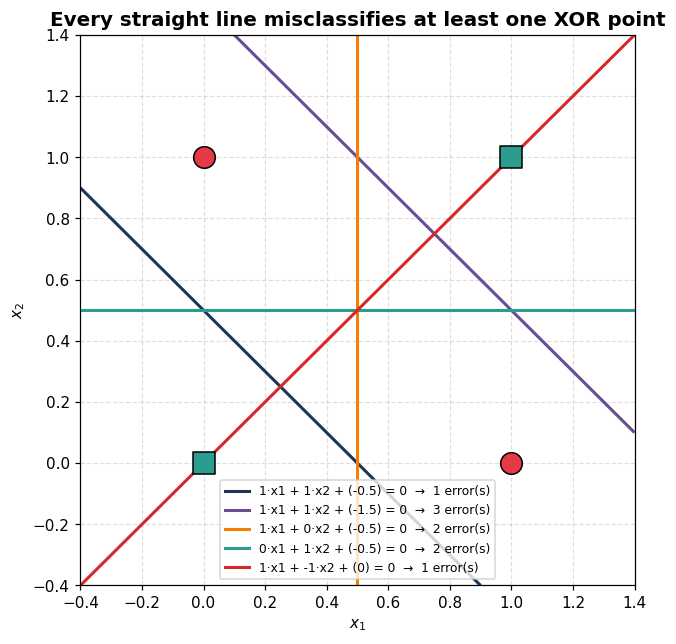

In [51]:
lines = [(1, 1, -0.5), (1, 1, -1.5), (1, 0, -0.5), (0, 1, -0.5), (1, -1, 0)]
cols = ['#1d3557', '#6a4c93', '#f77f00', '#2a9d8f', '#d62828']
xx, yy = np.meshgrid(np.linspace(-0.4, 1.4, 300), np.linspace(-0.4, 1.4, 300))
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for (w1, w2, b), c in zip(lines, cols):
    errs = int((((X @ [w1, w2] + b) > 0).astype(int) != y).sum())
    ax.contour(xx, yy, w1 * xx + w2 * yy + b, levels=[0], colors=[c], linewidths=2)
    ax.plot([], [], c=c, lw=2, label=f'{w1}·x1 + {w2}·x2 + ({b}) = 0  →  {errs} error(s)')
ax.scatter(*X[y == 0].T, c='#2a9d8f', marker='s', s=200, edgecolor='black', zorder=3)
ax.scatter(*X[y == 1].T, c='#e63946', marker='o', s=200, edgecolor='black', zorder=3)
ax.set(xlim=(-0.4, 1.4), ylim=(-0.4, 1.4), xlabel='$x_1$', ylabel='$x_2$')
ax.set_title('Every straight line misclassifies at least one XOR point', fontsize=13, fontweight='bold')
ax.legend(fontsize=8, loc='lower center'); ax.grid(True, ls='--', alpha=0.4); plt.show()

## Task 6 — How a hidden layer enables nonlinear decision boundaries

* A single neuron can only draw **one** straight line. A **hidden layer** contains several neurons, and each one draws its **own** line, so the network now has several half-planes to work with.
* The output neuron does not look at the raw inputs; it looks at the **hidden activations** $h = \sigma(W_1x + b_1)$. The hidden layer therefore acts as a **feature extractor** that *re-maps* the inputs into a new space.
* In that new space the XOR classes are **linearly separable**, so the output neuron $\hat y = \sigma(W_2h + b_2)$ can separate them with a single line. Seen from the original input space, combining several lines gives a **curved / piece-wise region** — a nonlinear boundary.
* The **nonlinear activation** (sigmoid) is essential: without it, stacking layers collapses to $W_2(W_1x+b_1)+b_2 = W'x+b'$, which is again just one linear map.

*Intuition for XOR:* one hidden unit can learn "x1 OR x2", another "x1 AND x2"; the output then fires for "OR but NOT AND" — which is exactly XOR.

In [52]:
# Intuition: XOR = (x1 OR x2) AND NOT (x1 AND x2), built from two linear (threshold) units + one output unit
h_or, h_and = (x1 | x2), (x1 & x2)
pd.DataFrame({'x1': x1, 'x2': x2, 'h1 = OR': h_or, 'h2 = AND': h_and, 'out = h1 AND NOT h2': h_or & (1 - h_and)})

,x1,x2,h1 = OR,h2 = AND,out = h1 AND NOT h2
0,0,0,0,0,0
1,0,1,1,0,1
2,1,0,1,0,1
3,1,1,1,1,0


## Task 7 — MLP architecture capable of solving XOR (2 – 4 – 1)

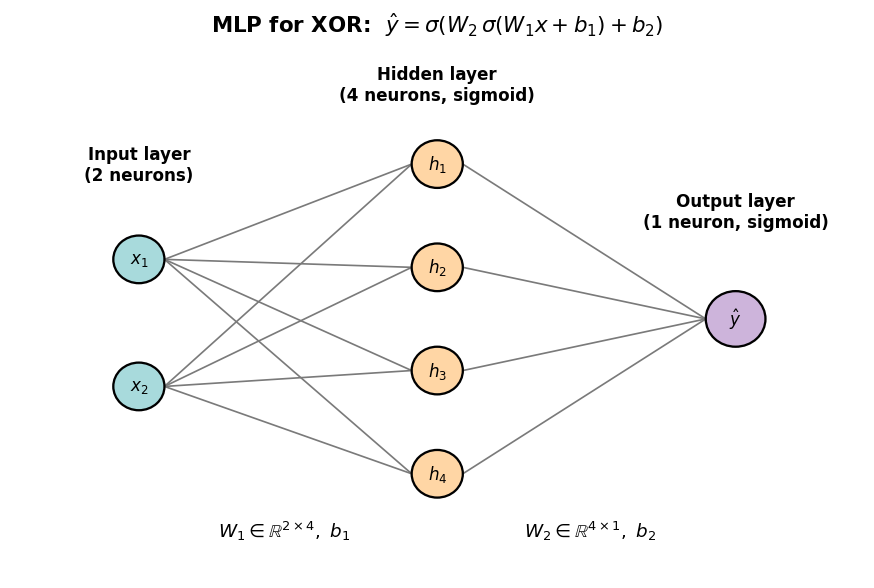

In [53]:
fig, ax = plt.subplots(figsize=(10, 6)); ax.set_xlim(0, 10); ax.set_ylim(0, 6.4); ax.axis('off')
ins  = [(1.5, 4.0), (1.5, 2.4)]
hid  = [(5.0, 5.2), (5.0, 3.9), (5.0, 2.6), (5.0, 1.3)]
out  = (8.5, 3.25)
for a in ins:
    for b in hid: ax.plot([a[0] + .3, b[0] - .3], [a[1], b[1]], color='#7a7a7a', lw=1.1, zorder=1)
for h in hid: ax.plot([h[0] + .3, out[0] - .35], [h[1], out[1]], color='#7a7a7a', lw=1.1, zorder=1)
def draw(pts, lab, color, r):
    for i, (x, y_) in enumerate(pts, 1):
        ax.add_patch(Circle((x, y_), r, fc=color, ec='black', lw=1.5, zorder=3)); ax.text(x, y_, lab.format(i), ha='center', va='center', fontsize=11, fontweight='bold', zorder=4)
draw(ins, '$x_{}$', '#a8dadc', .3); draw(hid, '$h_{}$', '#ffd6a5', .3); draw([out], r'$\hat{{y}}$', '#cdb4db', .35)
for x, t in [(1.5, 'Input layer\n(2 neurons)'), (5.0, 'Hidden layer\n(4 neurons, sigmoid)'), (8.5, 'Output layer\n(1 neuron, sigmoid)')]:
    ax.text(x, 6.0 if x == 5.0 else 5.0 if x == 1.5 else 4.4, t, ha='center', fontsize=11, fontweight='bold')
ax.text(3.2, 0.5, r'$W_1 \in \mathbb{R}^{2\times4},\ b_1$', ha='center', fontsize=12); ax.text(6.8, 0.5, r'$W_2 \in \mathbb{R}^{4\times1},\ b_2$', ha='center', fontsize=12)
ax.set_title('MLP for XOR:  $\\hat{y}=\\sigma(W_2\\,\\sigma(W_1x+b_1)+b_2)$', fontsize=14, fontweight='bold', pad=24); plt.show()

## Task 8 — XOR classifier in PyTorch (1 hidden layer, sigmoid, Binary Cross-Entropy)

| Setting | Value |
|---|---|
| Architecture | 2 → 4 → 1 |
| Activations | Sigmoid (hidden and output) |
| Loss | Binary Cross-Entropy (`nn.BCELoss`) |
| Optimizer | Adam, learning rate 0.05 |
| Epochs | 2000 (full batch) |

In [54]:
torch.manual_seed(7)
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y.reshape(-1, 1), dtype=torch.float32)

model = nn.Sequential(nn.Linear(2, 4), nn.Sigmoid(), nn.Linear(4, 1), nn.Sigmoid())
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=4, out_features=1, bias=True)
  (3): Sigmoid()
)
Trainable parameters: 17


In [55]:
EPOCHS, losses, accs = 2000, [], []
for ep in range(1, EPOCHS + 1):
    optimizer.zero_grad()
    out = model(X_t)
    loss = criterion(out, y_t)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    accs.append(((out >= 0.5).float() == y_t).float().mean().item())
    if ep == 1 or ep % 250 == 0:
        print(f'Epoch {ep:4d}/{EPOCHS} | loss = {loss.item():.6f} | accuracy = {accs[-1]*100:.0f}%')

Epoch    1/2000 | loss = 0.696667 | accuracy = 50%
Epoch  250/2000 | loss = 0.015885 | accuracy = 100%
Epoch  500/2000 | loss = 0.004775 | accuracy = 100%
Epoch  750/2000 | loss = 0.002432 | accuracy = 100%
Epoch 1000/2000 | loss = 0.001499 | accuracy = 100%
Epoch 1250/2000 | loss = 0.001021 | accuracy = 100%
Epoch 1500/2000 | loss = 0.000740 | accuracy = 100%
Epoch 1750/2000 | loss = 0.000559 | accuracy = 100%
Epoch 2000/2000 | loss = 0.000436 | accuracy = 100%


## Task 9 — Training loss over epochs

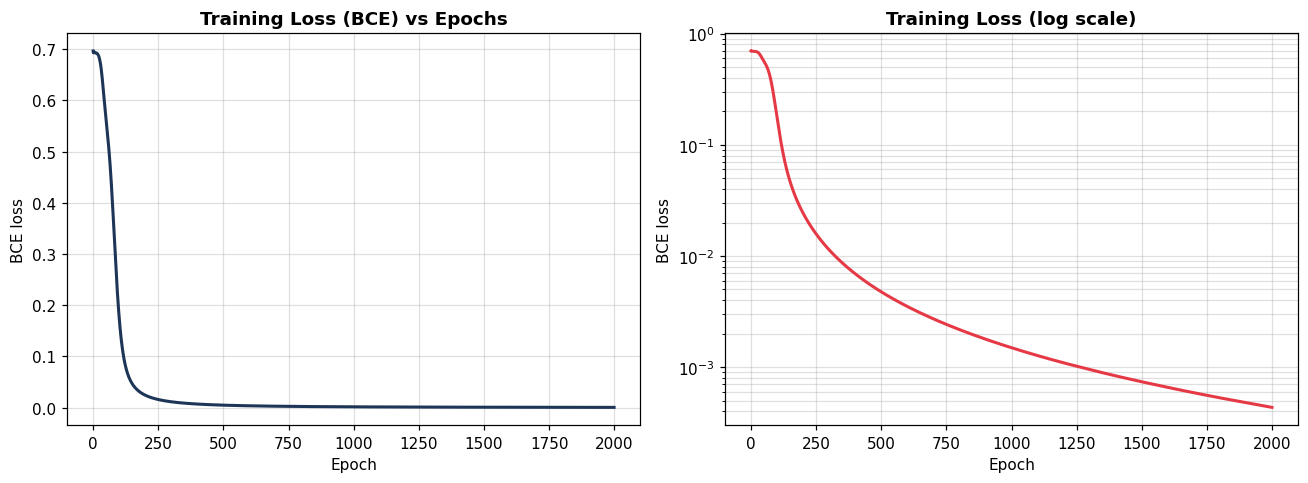

In [56]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot(losses, color='#1d3557', lw=2); a1.set(title='Training Loss (BCE) vs Epochs', xlabel='Epoch', ylabel='BCE loss'); a1.grid(alpha=.4)
a2.plot(losses, color='#e63946', lw=2); a2.set_yscale('log'); a2.set(title='Training Loss (log scale)', xlabel='Epoch', ylabel='BCE loss'); a2.grid(alpha=.4, which='both')
for a in (a1, a2): a.title.set_fontweight('bold')
plt.tight_layout(); plt.show()

## Task 10 — Final prediction accuracy

In [57]:
model.eval()
with torch.no_grad():
    predictions = model(X_t)
    prob = np.asarray(predictions.detach().cpu().tolist()).ravel()
    final_loss = criterion(predictions, y_t).item()
cls = (prob >= 0.5).astype(int)
print('Final Model Performance'); print('=' * 32)
print(f'Final BCE loss : {final_loss:.6f}')
print(f'Final accuracy : {(cls == y).mean() * 100:.2f}%')
pd.DataFrame({'x1': x1, 'x2': x2, 'Actual': y, 'Predicted probability': prob.round(4), 'Predicted class': cls, 'Correct?': np.where(cls == y, '✔', '✘')})

Final Model Performance
Final BCE loss : 0.000435
Final accuracy : 100.00%


,x1,x2,Actual,Predicted probability,Predicted class,Correct?
0,0,0,0,0.0001,0,✔
1,0,1,1,0.9995,1,✔
2,1,0,1,0.9995,1,✔
3,1,1,0,0.0008,0,✔


### Decision boundary visualization

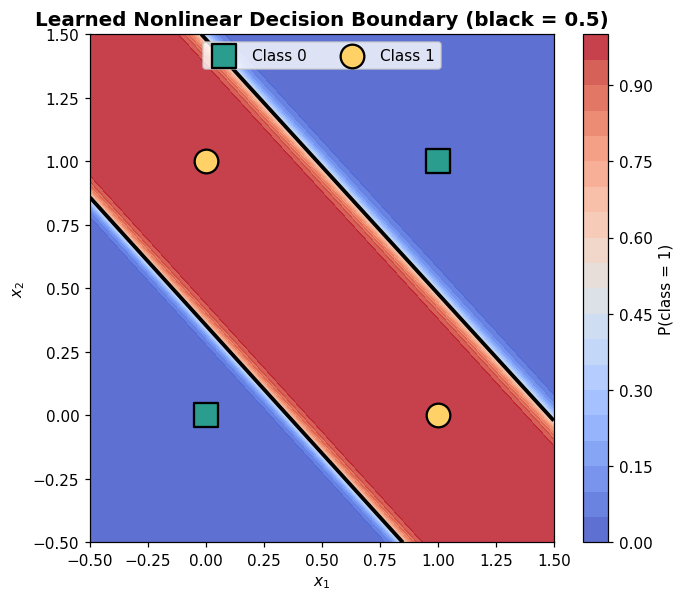

In [58]:
gx, gy = np.meshgrid(np.linspace(-0.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
with torch.no_grad():
    grid = torch.tensor(
        np.c_[gx.ravel(), gy.ravel()],
        dtype=torch.float32
    )
    zz = np.asarray(
        model(grid).detach().cpu().tolist(),
        dtype=float
    ).reshape(gx.shape)
fig, ax = plt.subplots(figsize=(6.8, 6))
cf = ax.contourf(gx, gy, zz, levels=20, cmap='coolwarm', alpha=.85)
ax.contour(gx, gy, zz, levels=[0.5], colors='black', linewidths=2.5)
ax.scatter(*X[y == 0].T, c='#2a9d8f', marker='s', s=240, edgecolor='black', lw=1.5, label='Class 0', zorder=3)
ax.scatter(*X[y == 1].T, c='#ffd166', marker='o', s=240, edgecolor='black', lw=1.5, label='Class 1', zorder=3)
plt.colorbar(cf, label='P(class = 1)'); ax.legend(loc='upper center', ncol=2)
ax.set(xlabel='$x_1$', ylabel='$x_2$'); ax.set_title('Learned Nonlinear Decision Boundary (black = 0.5)', fontsize=13, fontweight='bold'); plt.show()

### Hidden-layer representation (why the MLP works)

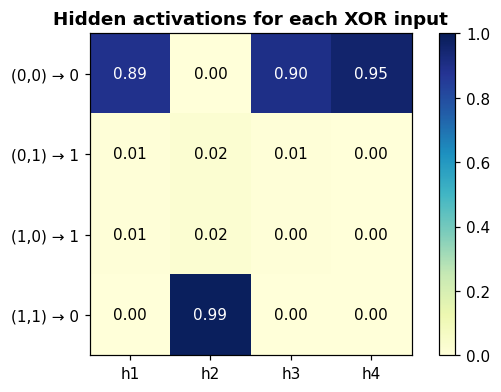

In [59]:
with torch.no_grad():
    H = torch.sigmoid(model[0](X_t)).detach().cpu().tolist()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
im = ax.imshow(H, cmap='YlGnBu', vmin=0, vmax=1)
ax.set_xticks(range(4), [f'h{i}' for i in range(1, 5)]); ax.set_yticks(range(4), [f'({a},{b}) → {t}' for a, b, t in zip(x1, x2, y)])
for i in range(4):
    for j in range(4): ax.text(j, i, f'{H[i][j]:.2f}', ha='center', va='center', color='white' if H[i][j] > .5 else 'black')
ax.set_title('Hidden activations for each XOR input', fontweight='bold'); plt.colorbar(im); plt.show()

## Short Discussion (≈200 words)

The single-layer perceptron computes one linear function, $\hat y=f(w_1x_1+w_2x_2+b)$, so its decision boundary is always a straight line. The XOR problem places the two classes on opposite diagonals of the unit square, and the proof in Task 4 shows that the four required inequalities contradict each other. The brute-force search confirmed this: out of more than 200,000 candidate lines none exceeded 75 % accuracy, and the perceptron-rule experiment never reached 100 % on XOR while it solved AND, OR and NAND easily.

Adding a hidden layer removes this limit. Each hidden neuron draws its own line, and the nonlinear sigmoid lets the layer re-map the inputs into a space in which the output neuron can separate the classes with one line. A 2-4-1 MLP trained with Binary Cross-Entropy and Adam reduced the loss from about 0.70 to below 0.001 over 2000 epochs and reached **100 % accuracy**, with predicted probabilities close to 0 and 1. The contour plot shows a curved decision region, and the hidden-activation heat-map shows that the four inputs become linearly separable in hidden space.

**Conclusion:** the XOR problem exposes the representational limit of the single-layer perceptron, and hidden layers with nonlinear activations are what give neural networks the power to learn nonlinear decision boundaries — the foundation of modern deep learning.